### **0. Environment Setup**

In [1]:
#Import Libs
import sklearn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from cycler import cycler

In [2]:
#Define Colors Palette and Standards for Illustrations
RED, DARK, GRAY, LIGHT, SOFT = "#CD2027", "#404040", "#7F7F7F", "#D9D9D9", "#E9A0A3"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.prop_cycle": cycler(color=[RED, DARK, SOFT, GRAY]),
})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

### **1. Dimensionality Reduction**

**Dimensionality reduction** means representing a dataset with **fewer attributes (dimensions)** while keeping as much useful information as possible. About the curse of dimensionality, as the number of attributes grows:

* the space grows **exponentially**, so the data become **sparse**;
* distances between points tend to become **almost equal**, which hurts algorithms such as k-NN and K-Means;
* the risk of **overfitting** and the computational cost increase;
* redundant or irrelevant attributes only add **noise**.

For example, with 500 random points, we measure the **relative contrast** between the farthest and the nearest neighbour of a random query point:

$$\text{relative contrast} = \frac{d_{max} - d_{min}}{d_{min}}$$

When it approaches 0, "near" and "far" are almost the same thing.

In [3]:
#Function to Create the Distance Contrast
def relative_contrast(n_points, n_dims, n_queries=30, seed=RANDOM_STATE):
    """(farthest - nearest) / nearest distance to a random query, averaged over queries."""
    rng = np.random.default_rng(seed)
    values = []
    for _ in range(n_queries):
        points = rng.random((n_points, n_dims))
        query = rng.random(n_dims)
        dist = np.linalg.norm(points - query, axis=1)
        values.append((dist.max() - dist.min()) / dist.min())
    return float(np.mean(values))

dims = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]
contrast = pd.DataFrame({"dimensions": dims,
                         "relative_contrast": [relative_contrast(500, d) for d in dims]})
contrast

,dimensions,relative_contrast
0,1,4215.102
1,2,53.751
2,5,6.383
3,10,2.462
4,20,1.258
5,50,0.623
6,100,0.406
7,200,0.265
8,500,0.158
9,1000,0.110


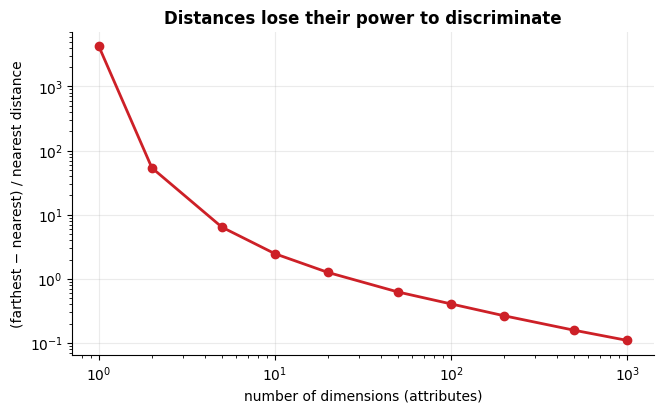

In [4]:
#Distances lose their power to discriminate
plt.figure()
plt.plot(contrast["dimensions"], contrast["relative_contrast"], marker="o", color=RED, lw=2)
plt.xscale("log"); plt.yscale("log")
plt.xlabel("number of dimensions (attributes)")
plt.ylabel("(farthest − nearest) / nearest distance")
plt.title("Distances lose their power to discriminate")
plt.show()

,noise_attributes,total_attributes,cv_accuracy
0,0,5,0.997
1,5,10,0.988
2,10,15,0.985
3,20,25,0.920
4,50,55,0.860
5,100,105,0.757
6,200,205,0.690
7,500,505,0.645


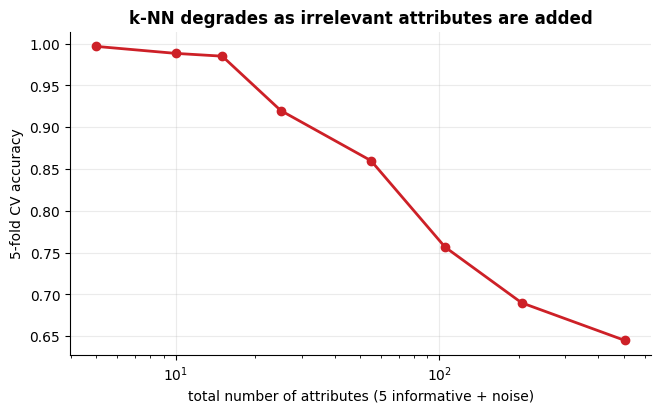

In [5]:
#Second example: k-NN Accuracy with Irrelevant Attributes ( Classification )
from sklearn.datasets import make_classification
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_info, y_info = make_classification(n_samples=600, n_features=5, n_informative=5, n_redundant=0,
                                     n_clusters_per_class=1, class_sep=1.5, random_state=RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)

rows = []
for n_noise in [0, 5, 10, 20, 50, 100, 200, 500]:
    X_ = np.hstack([X_info, rng.normal(size=(len(X_info), n_noise))])
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
    rows.append((n_noise, 5 + n_noise, cross_val_score(knn, X_, y_info, cv=5).mean()))

noise_df = pd.DataFrame(rows, columns=["noise_attributes", "total_attributes", "cv_accuracy"])
display(noise_df)

plt.figure()
plt.plot(noise_df["total_attributes"], noise_df["cv_accuracy"], marker="o", color=RED, lw=2)
plt.xscale("log")
plt.xlabel("total number of attributes (5 informative + noise)")
plt.ylabel("5-fold CV accuracy")
plt.title("k-NN degrades as irrelevant attributes are added")
plt.show()

### **2. Feature selection**

| | **Feature selection** |
|---|---|
| Idea | Choose a **subset** of the original attributes |
| Keeps original attributes? | ✅ Yes |
| Interpretability | High |
| Families / examples | **Filter** (variance, correlation, χ², mutual information) · **Wrapper** (RFE, forward/backward) · **Embedded** (Lasso, tree importance) · **Rough Sets** (reducts) |

<br>

| | **Feature extraction** |
|---|---|
| Idea | Create **new attributes** combining the original ones |
| Keeps original attributes? | ❌ No |
| Interpretability | Lower |
| Families / examples | **PCA** · **SVD** · LDA · t-SNE / UMAP (visualisation) · autoencoders |

In [6]:
#Example of Feature Selection with Wine Dataset
from sklearn.datasets import load_wine
X_wine, y_wine = load_wine(return_X_y=True, as_frame=True)
print("shape:", X_wine.shape, "| classes:", sorted(y_wine.unique().tolist()))
X_wine.head()

shape: (178, 13) | classes: [0, 1, 2]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [7]:
#Example with Variance Threshold ( Uses the Scale - compare attributes on a common scale (e.g. after MinMaxScaler) )
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import MinMaxScaler

X_demo = X_wine.copy()
X_demo["constant"] = 1.0
X_demo["almost_constant"] = 0.0
X_demo.loc[X_demo.index[0], "almost_constant"] = 1.0          # only one row differs

X_scaled = pd.DataFrame(MinMaxScaler().fit_transform(X_demo), columns=X_demo.columns)
print("Variance of each attribute after min-max scaling:")
display(X_scaled.var().sort_values().round(4).to_frame("variance").T)

vt = VarianceThreshold(threshold=0.01).fit(X_scaled)
print("removed:", list(X_demo.columns[~vt.get_support()]))

Variance of each attribute after min-max scaling:


,constant,almost_constant,ash,magnesium,alcalinity_of_ash,proanthocyanins,hue,color_intensity,flavanoids,alcohol,total_phenols,malic_acid,proline,nonflavanoid_phenols,od280/od315_of_diluted_wines
variance,0.0,0.006,0.021,0.024,0.03,0.033,0.035,0.039,0.044,0.046,0.047,0.049,0.051,0.055,0.068


removed: ['constant', 'almost_constant']


dropped: ['flavanoids', 'od280/od315_of_diluted_wines']
kept   : ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'proline']


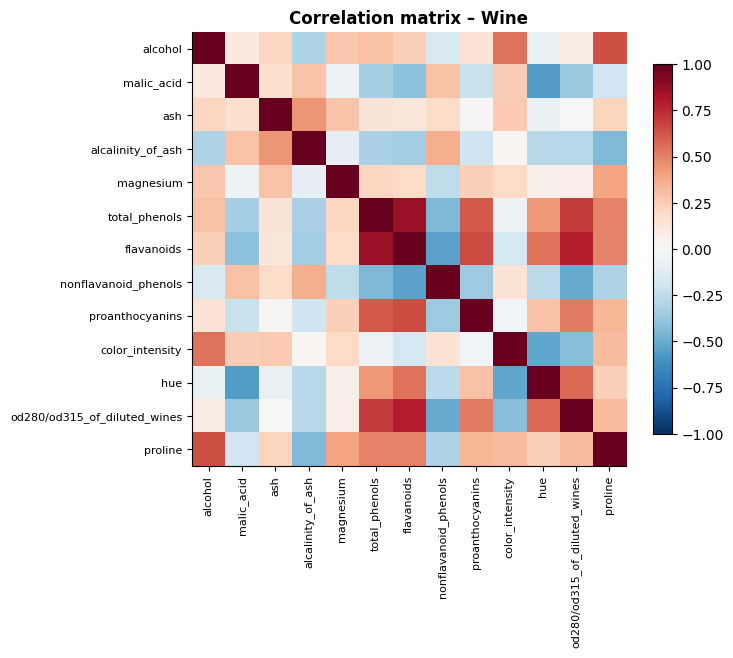

In [8]:
#Example with Correlation Filter ( If highly correlated attributes are redundant: We can keep one of them )
from sklearn.base import BaseEstimator, TransformerMixin

class CorrelationFilter(BaseEstimator, TransformerMixin):
    """Drop one attribute of every pair whose absolute correlation exceeds `threshold`."""
    def __init__(self, threshold=0.9):
        self.threshold = threshold

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        corr = X.corr().abs()
        upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))   # upper triangle only
        self.to_drop_ = [c for c in upper.columns if (upper[c] > self.threshold).any()]
        self.keep_ = [c for c in X.columns if c not in self.to_drop_]
        return self

    def transform(self, X):
        return pd.DataFrame(X)[self.keep_].to_numpy()

cf = CorrelationFilter(threshold=0.7).fit(X_wine)
print("dropped:", cf.to_drop_)
print("kept   :", cf.keep_)

corr = X_wine.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
ax.grid(False); ax.set_title("Correlation matrix – Wine")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

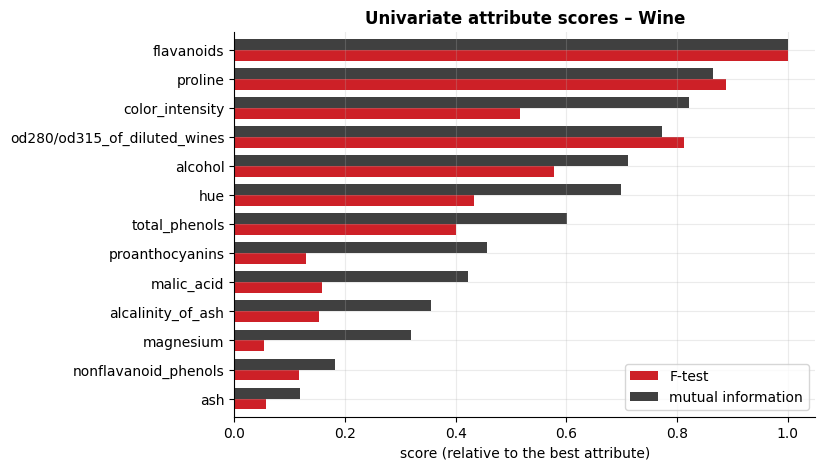

Top 5 (F-test)             : ['flavanoids', 'proline', 'od280/od315_of_diluted_wines', 'alcohol', 'color_intensity']
Top 5 (mutual information) : ['flavanoids', 'proline', 'color_intensity', 'od280/od315_of_diluted_wines', 'alcohol']


In [9]:
#Example with ANOVA F-test ( Score each attribute individually against the target and keeps the k best )
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from functools import partial

f_scores = SelectKBest(f_classif, k="all").fit(X_wine, y_wine).scores_
mi_scores = SelectKBest(partial(mutual_info_classif, random_state=RANDOM_STATE), k="all").fit(X_wine, y_wine).scores_

scores = pd.DataFrame({"F-test": f_scores, "mutual information": mi_scores}, index=X_wine.columns)
scores_norm = scores / scores.max()                                    # scale to [0, 1] to compare

scores_norm.sort_values("mutual information").plot.barh(figsize=(7.5, 5), width=0.75)
plt.xlabel("score (relative to the best attribute)")
plt.title("Univariate attribute scores – Wine")
plt.show()

print("Top 5 (F-test)             :", list(scores["F-test"].nlargest(5).index))
print("Top 5 (mutual information) :", list(scores["mutual information"].nlargest(5).index))

#### **Wrapper and Embedded Methods**

* **RFE (wrapper):** trains a model, **removes the weakest attribute** and repeats
* **Random Forest (embedded):** `SelectFromModel` keeps the attributes the model finds most important

In [10]:
#Example with RFE ( Wrapper ) and Random Forest ( Embedded )
from sklearn.feature_selection import RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

X_wine_std = StandardScaler().fit_transform(X_wine)

rfe = RFE(LogisticRegression(max_iter=1000), n_features_to_select=5).fit(X_wine_std, y_wine)
print("RFE (5 attributes)        :", list(X_wine.columns[rfe.support_]))

sfm = SelectFromModel(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
                      max_features=5, threshold=-np.inf).fit(X_wine, y_wine)
print("Random Forest (5 attributes):", list(X_wine.columns[sfm.get_support()]))

RFE (5 attributes)        : ['alcohol', 'flavanoids', 'color_intensity', 'hue', 'proline']
Random Forest (5 attributes): ['alcohol', 'flavanoids', 'color_intensity', 'od280/od315_of_diluted_wines', 'proline']


#### **Comparing the Strategies**

Selectors inside a `Pipeline` are refitted in each fold – no leakage (see section 7).

In [11]:
#Compare the Selection Strategies with Cross-Validation
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
clf = lambda: LogisticRegression(max_iter=1000)

pipelines = {
    "all 13 attributes":        make_pipeline(StandardScaler(), clf()),
    "correlation filter (0.7)": make_pipeline(StandardScaler(), CorrelationFilter(0.7), clf()),
    "SelectKBest F-test (k=5)": make_pipeline(StandardScaler(), SelectKBest(f_classif, k=5), clf()),
    "RFE (5)":                  make_pipeline(StandardScaler(), RFE(LogisticRegression(max_iter=1000), n_features_to_select=5), clf()),
    "Random Forest (5)":        make_pipeline(StandardScaler(),
                                              SelectFromModel(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
                                                              max_features=5, threshold=-np.inf), clf()),
}

rows = []
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X_wine, y_wine, cv=cv5)
    n_feat = pipe[:-1].fit(X_wine, y_wine).transform(X_wine).shape[1]          # only to report how many were kept
    rows.append((name, n_feat, scores.mean(), scores.std()))

selection_results = pd.DataFrame(rows, columns=["method", "n_features", "cv_accuracy", "cv_std"])
selection_results

,method,n_features,cv_accuracy,cv_std
0,all 13 attributes,13,0.983,0.014
1,correlation filter (0.7),11,0.978,0.011
2,SelectKBest F-test (k=5),5,0.966,0.033
3,RFE (5),5,0.972,0.018
4,Random Forest (5),5,0.978,0.021


With far fewer attributes the accuracy stays **close to the full model**, and the original attributes are kept (easy to explain).

### **3. PCA – Principal Component Analysis**

**PCA** finds **orthogonal directions** (principal components) that capture the **maximum variance**. Each component is a **linear combination** of the original attributes.

1. **Standardise** the attributes (mean 0, standard deviation 1)
2. **Covariance matrix:** $\Sigma = \dfrac{1}{n-1} X_{c}^{T} X_{c}$
3. **Eigen-decomposition:** $\Sigma v = \lambda v$ (directions $v$, variances $\lambda$)
4. **Sort** the components by decreasing $\lambda$
5. **Project** onto the first $k$ components: $Z = X_{c} W_k$

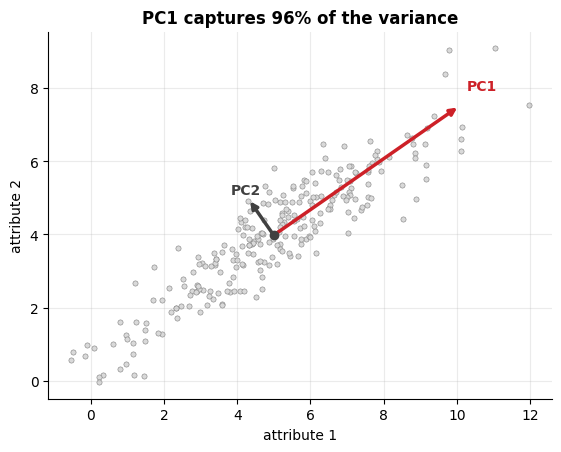

In [12]:
#PCA Intuition in Two Dimensions ( Correlated Data and the Principal Components )
rng = np.random.default_rng(RANDOM_STATE)
Z = rng.normal(size=(250, 2)) @ np.array([[2.4, 0.0], [1.5, 0.7]]).T + np.array([5, 4])    # correlated 2-D cloud

from sklearn.decomposition import PCA
pca2 = PCA(n_components=2).fit(Z)
mu = Z.mean(axis=0)

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(Z[:, 0], Z[:, 1], s=14, color=LIGHT, edgecolor=GRAY, lw=0.4)
for k, (color, label) in enumerate(zip([RED, DARK], ["PC1", "PC2"])):
    vec = pca2.components_[k] * np.sqrt(pca2.explained_variance_[k]) * 2.2
    ax.annotate("", xy=mu + vec, xytext=mu, arrowprops=dict(arrowstyle="-|>", color=color, lw=2.5))
    ax.text(*(mu + vec * 1.12), label, color=color, fontweight="bold", ha="center")
ax.scatter(*mu, color=DARK, zorder=5)
ax.set_aspect("equal"); ax.set_xlabel("attribute 1"); ax.set_ylabel("attribute 2")
ax.set_title(f"PC1 captures {pca2.explained_variance_ratio_[0]*100:.0f}% of the variance")
plt.show()

#### **PCA from Scratch**

The five steps in NumPy give the same result as `sklearn.decomposition.PCA`.

In [13]:
#PCA from Scratch ( NumPy ) vs sklearn
def pca_from_scratch(X, n_components):
    Xc = X - X.mean(axis=0)                       # 1) center (X is already standardised)
    cov = np.cov(Xc, rowvar=False)                # 2) covariance matrix (p x p)
    eigvals, eigvecs = np.linalg.eigh(cov)        # 3) eigen-decomposition (ascending order)
    order = np.argsort(eigvals)[::-1]             # 4) sort by decreasing variance
    eigvals, eigvecs = eigvals[order], eigvecs[:, order]
    components = eigvecs[:, :n_components].T
    scores = Xc @ components.T                    # 5) project
    return scores, components, eigvals

scores_np, comps_np, eig_np = pca_from_scratch(X_wine_std, n_components=2)
pca_ref = PCA(n_components=2).fit(X_wine_std)

print("components equal (up to sign):", np.allclose(np.abs(comps_np), np.abs(pca_ref.components_)))
print("eigenvalues == explained_variance_:", np.allclose(eig_np[:2], pca_ref.explained_variance_))
print("variance ratio of PC1, PC2:", (eig_np[:2] / eig_np.sum()).round(3))

components equal (up to sign): True
eigenvalues == explained_variance_: True
variance ratio of PC1, PC2: [0.362 0.192]


#### **Number of Components**

Keep enough components for **95 %** of the variance: `PCA(n_components=0.95)`.

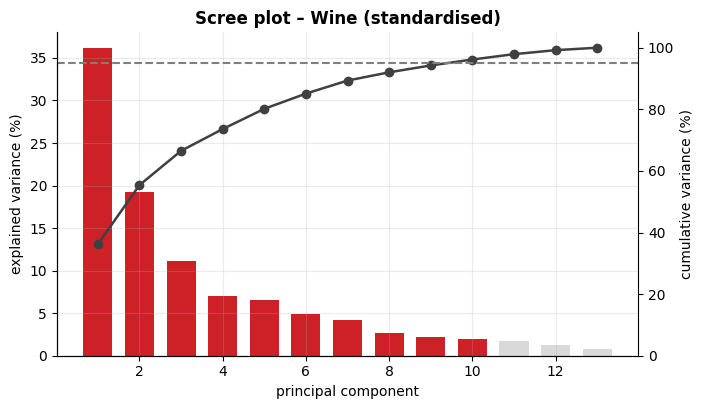

components needed for 95% of the variance: 10 of 13 (96.2% retained)


In [14]:
#Scree Plot and Cumulative Variance
pca_full = PCA().fit(X_wine_std)
ratio = pca_full.explained_variance_ratio_
cum = ratio.cumsum()

fig, ax = plt.subplots()
ax.bar(range(1, 14), ratio * 100, color=[RED if (i == 0 or cum[i - 1] < 0.95) else LIGHT for i in range(13)], width=0.7)
ax2 = ax.twinx()
ax2.plot(range(1, 14), cum * 100, color=DARK, marker="o", lw=1.8)
ax2.axhline(95, color=GRAY, ls="--"); ax2.set_ylim(0, 105); ax2.grid(False)
ax2.spines["right"].set_visible(True); ax2.set_ylabel("cumulative variance (%)")
ax.set_xlabel("principal component"); ax.set_ylabel("explained variance (%)")
ax.set_title("Scree plot – Wine (standardised)")
plt.show()

pca95 = PCA(n_components=0.95).fit(X_wine_std)
print(f"components needed for 95% of the variance: {pca95.n_components_} of {X_wine.shape[1]} "
      f"({pca95.explained_variance_ratio_.sum()*100:.1f}% retained)")

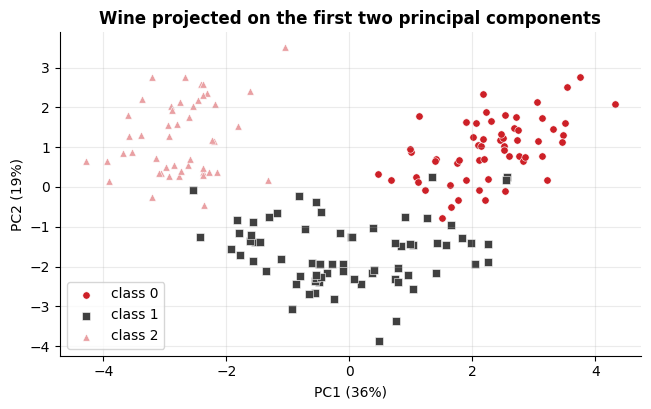

In [15]:
#Project the Wine Dataset in 2 Components
Z_wine = PCA(n_components=2).fit_transform(X_wine_std)
fig, ax = plt.subplots()
for cls, color, marker in zip([0, 1, 2], [RED, DARK, SOFT], ["o", "s", "^"]):
    mask = (y_wine == cls).to_numpy()
    ax.scatter(Z_wine[mask, 0], Z_wine[mask, 1], color=color, marker=marker, s=28, edgecolor="white", lw=0.4, label=f"class {cls}")
ax.set_xlabel(f"PC1 ({pca_full.explained_variance_ratio_[0]*100:.0f}%)")
ax.set_ylabel(f"PC2 ({pca_full.explained_variance_ratio_[1]*100:.0f}%)")
ax.set_title("Wine projected on the first two principal components"); ax.legend()
plt.show()

#### **Standardisation**

PCA looks for **variance**: an attribute in larger units (e.g. `proline`) dominates PC1 if the data are not standardised.

In [16]:
#PCA Without vs With Standardisation
pca_raw = PCA().fit(X_wine)                                 # WITHOUT standardising
cmp = pd.DataFrame({
    "variance ratio – raw": pca_raw.explained_variance_ratio_[:4],
    "variance ratio – standardised": pca_full.explained_variance_ratio_[:4],
}, index=["PC1", "PC2", "PC3", "PC4"])
display(cmp.round(4))

top = pd.Series(pca_raw.components_[0], index=X_wine.columns).abs().sort_values(ascending=False)
print("Largest loadings of PC1 without standardising:")
print(top.head(3).round(3))

,variance ratio – raw,variance ratio – standardised
PC1,9.981e-01,0.362
PC2,1.700e-03,0.192
PC3,1.000e-04,0.111
PC4,1.000e-04,0.071


Largest loadings of PC1 without standardising:
proline              1.000
magnesium            0.018
alcalinity_of_ash    0.005
dtype: float64


Without standardising, **PC1 is almost only `proline`** (> 99 % of the variance) – a scale artefact.

#### **Loadings and Reconstruction**

* `components_` holds the **weight** of each attribute in each component
* `inverse_transform` rebuilds the data: more components, less information lost

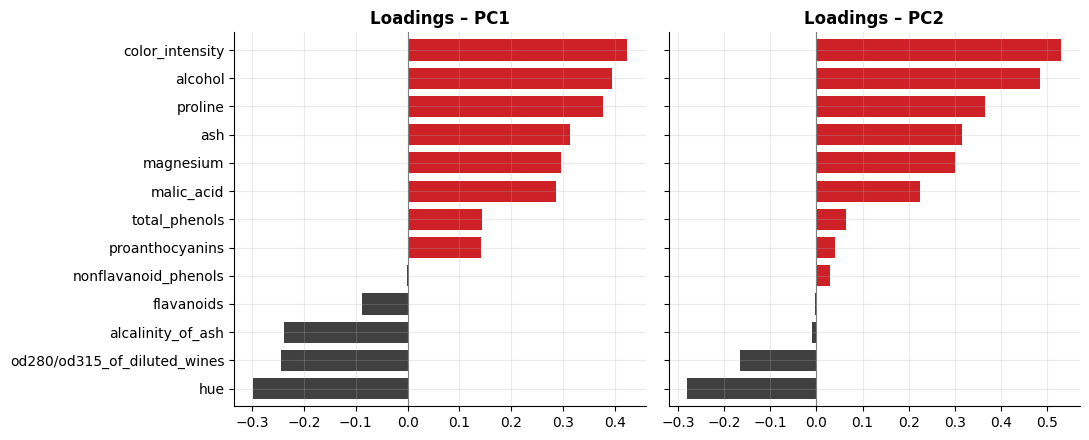

In [17]:
#Show the Loadings of PC1 and PC2
loadings = pd.DataFrame(pca_full.components_[:2].T, index=X_wine.columns, columns=["PC1", "PC2"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, pc in zip(axes, ["PC1", "PC2"]):
    loadings[pc].sort_values().plot.barh(ax=ax, color=[RED if v > 0 else DARK for v in loadings[pc].sort_values()], width=0.75)
    ax.set_title(f"Loadings – {pc}"); ax.axvline(0, color=GRAY, lw=0.8)
plt.tight_layout(); plt.show()

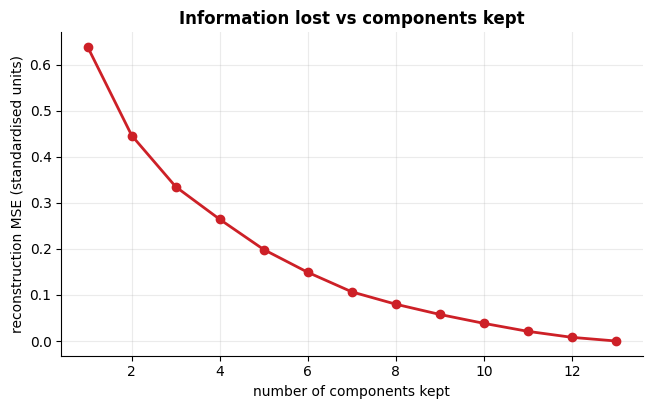

In [18]:
#Reconstruction Error by Number of Components
from sklearn.metrics import mean_squared_error

errors = []
for k in range(1, 14):
    p = PCA(n_components=k).fit(X_wine_std)
    rec = p.inverse_transform(p.transform(X_wine_std))
    errors.append(mean_squared_error(X_wine_std, rec))

plt.figure()
plt.plot(range(1, 14), errors, marker="o", color=RED, lw=2)
plt.xlabel("number of components kept"); plt.ylabel("reconstruction MSE (standardised units)")
plt.title("Information lost vs components kept")
plt.show()

#### **PCA on Images (Digits)**

1 797 images of 8×8 pixels (**64 attributes**) shown in 2 dimensions, plus the first components as images.

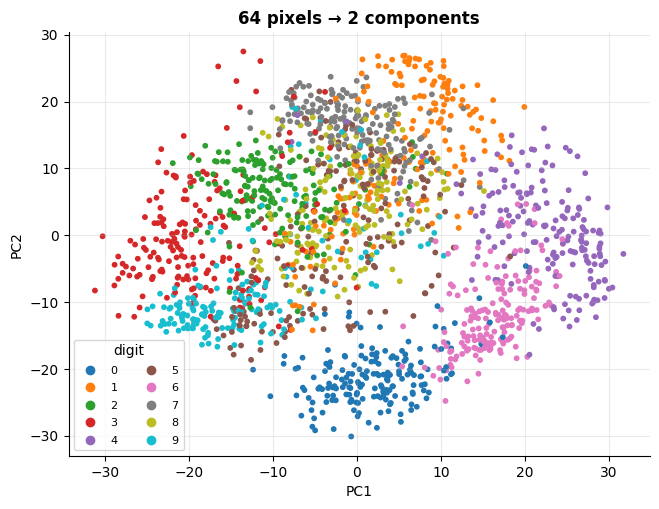

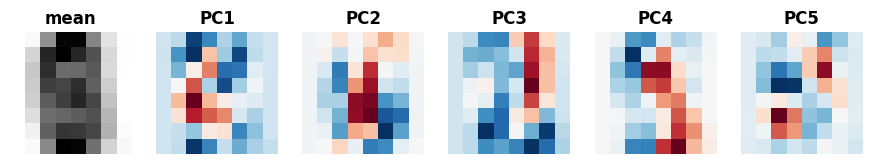

In [19]:
#PCA on the Digits Dataset ( 64 Pixels to 2 Components )
from sklearn.datasets import load_digits

digits = load_digits()
X_dig, y_dig = digits.data, digits.target
pca_dig = PCA(n_components=2).fit(X_dig)
Z_dig = pca_dig.transform(X_dig)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
sc = ax.scatter(Z_dig[:, 0], Z_dig[:, 1], c=y_dig, cmap="tab10", s=10)
ax.legend(*sc.legend_elements(), title="digit", ncol=2, fontsize=8, loc="best")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title("64 pixels → 2 components")
plt.show()

pca_dig10 = PCA(n_components=10).fit(X_dig)
fig, axes = plt.subplots(1, 6, figsize=(11, 2.2))
axes[0].imshow(pca_dig10.mean_.reshape(8, 8), cmap="gray_r"); axes[0].set_title("mean")
for i in range(5):
    axes[i + 1].imshow(pca_dig10.components_[i].reshape(8, 8), cmap="RdBu_r"); axes[i + 1].set_title(f"PC{i+1}")
for a in axes: a.axis("off")
plt.show()

#### **Factor Analysis (Related Technique)**

Models the data as **latent factors + noise**: $X = \Lambda F + \epsilon$. PCA explains the **total variance**; Factor Analysis, the **shared variance**.

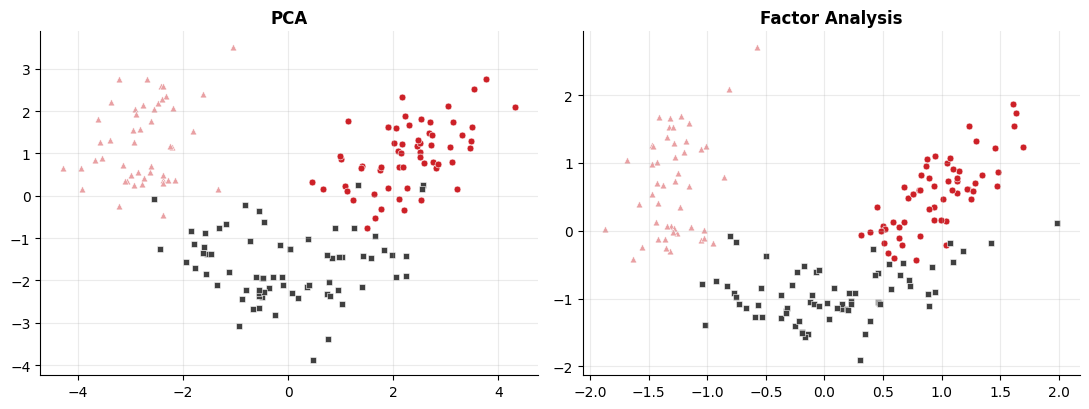

In [20]:
#Compare PCA with Factor Analysis
from sklearn.decomposition import FactorAnalysis

Z_fa = FactorAnalysis(n_components=2, random_state=RANDOM_STATE).fit_transform(X_wine_std)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, Zp, name in zip(axes, [Z_wine, Z_fa], ["PCA", "Factor Analysis"]):
    for cls, color, marker in zip([0, 1, 2], [RED, DARK, SOFT], ["o", "s", "^"]):
        m = (y_wine == cls).to_numpy()
        ax.scatter(Zp[m, 0], Zp[m, 1], color=color, marker=marker, s=24, edgecolor="white", lw=0.4)
    ax.set_title(name)
plt.tight_layout(); plt.show()

#### **PCA Pitfalls**

* **Standardise** attributes with different scales
* It is **linear** and sensitive to **outliers**
* Components are **harder to interpret**
* **Fit only on the training set** (use a `Pipeline` – see section 7)

### **4. SVD – Singular Value Decomposition**

Any $m \times n$ matrix $A$ can be factorised as $A = U \, \Sigma \, V^{T}$

* $U$: **left singular vectors** · $V^{T}$: **right singular vectors**
* $\Sigma$: **singular values** $\sigma_1 \ge \sigma_2 \ge \dots \ge 0$ (importance of each direction)
* Keeping the $k$ largest gives the **best rank-$k$ approximation**: $A_k = U_k \Sigma_k V_k^{T}$

In [21]:
#SVD of a Small Matrix ( Economy SVD )
A = np.array([[3, 1, 1],
              [-1, 3, 1],
              [2, 0, 4],
              [1, 2, 3]], dtype=float)                   # 4 x 3

U, S, Vt = np.linalg.svd(A, full_matrices=False)          # economy SVD
print("shapes  U:", U.shape, " S:", S.shape, " Vt:", Vt.shape)
print("singular values:", S.round(3))
print("A == U Σ Vᵀ ?", np.allclose(U @ np.diag(S) @ Vt, A))
print("rank of A:", np.linalg.matrix_rank(A))
print("σ² == eigenvalues of AᵀA ?", np.allclose(np.sort(S**2), np.sort(np.linalg.eigvalsh(A.T @ A))))

shapes  U: (4, 3)  S: (3,)  Vt: (3, 3)
singular values: [6.244 3.527 2.138]
A == U Σ Vᵀ ? True
rank of A: 3
σ² == eigenvalues of AᵀA ? True


#### **PCA = SVD**

PCA is the SVD of the **centred** data: the right singular vectors are the components and the variances are $\sigma_i^2 / (n-1)$.

In [22]:
#Check that PCA is the SVD of the Centred Data
Xc = X_wine_std - X_wine_std.mean(axis=0)
U_w, S_w, Vt_w = np.linalg.svd(Xc, full_matrices=False)
pca_ref = PCA().fit(X_wine_std)

n = Xc.shape[0]
print("components equal (up to sign)           :", np.allclose(np.abs(Vt_w), np.abs(pca_ref.components_)))
print("σ² / (n-1) == explained_variance_       :", np.allclose(S_w**2 / (n - 1), pca_ref.explained_variance_))

components equal (up to sign)           : True
σ² / (n-1) == explained_variance_       : True


#### **Image Compression**

Keeping $k$ singular values stores $k(m+n+1)$ numbers instead of $m \cdot n$.

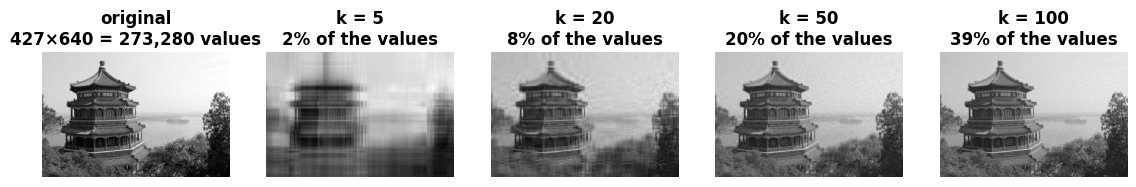

,k,values_stored,fraction_of_original,relative_error
0,5,5340,0.020,0.184
1,20,21360,0.078,0.136
2,50,53400,0.195,0.103
3,100,106800,0.391,0.074


In [23]:
#Image Compression with Low-Rank Approximation
from sklearn.datasets import load_sample_image

img = load_sample_image("china.jpg").astype(float).mean(axis=2)          # RGB → grey-scale
m, n = img.shape
U_i, S_i, Vt_i = np.linalg.svd(img, full_matrices=False)

def low_rank(k):
    return U_i[:, :k] @ np.diag(S_i[:k]) @ Vt_i[:k]

ks = [5, 20, 50, 100]
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
axes[0].imshow(img, cmap="gray"); axes[0].set_title(f"original\n{m}×{n} = {m*n:,} values")
rows = []
for ax, k in zip(axes[1:], ks):
    rec = low_rank(k)
    err = np.linalg.norm(img - rec) / np.linalg.norm(img)
    stored = k * (m + n + 1)
    ax.imshow(rec, cmap="gray"); ax.set_title(f"k = {k}\n{stored/(m*n)*100:.0f}% of the values")
    rows.append((k, stored, stored / (m * n), err))
for a in axes: a.axis("off")
plt.show()

pd.DataFrame(rows, columns=["k", "values_stored", "fraction_of_original", "relative_error"])

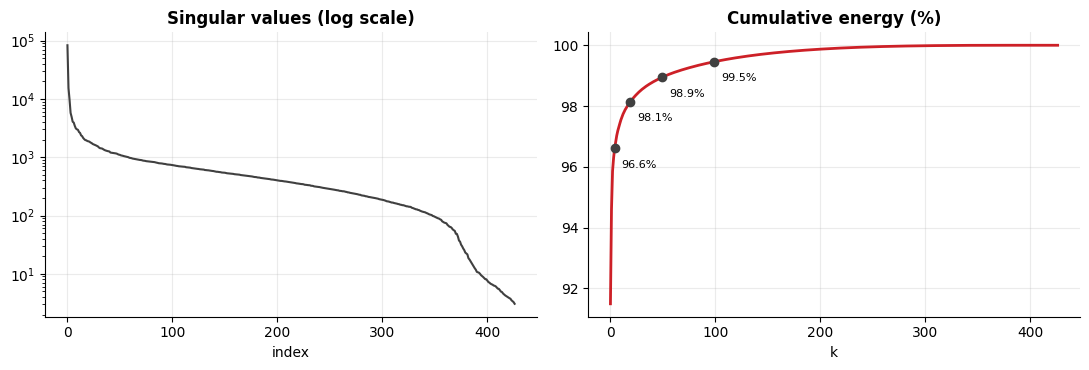

In [24]:
#Singular Values and Cumulative Energy
energy = (S_i**2).cumsum() / (S_i**2).sum()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].semilogy(S_i, color=DARK); axes[0].set_title("Singular values (log scale)"); axes[0].set_xlabel("index")
axes[1].plot(energy * 100, color=RED, lw=2); axes[1].set_title("Cumulative energy (%)"); axes[1].set_xlabel("k")
for k in ks:
    axes[1].scatter(k - 1, energy[k - 1] * 100, color=DARK, zorder=5)
    axes[1].annotate(f"{energy[k-1]*100:.1f}%", (k - 1, energy[k - 1] * 100), textcoords="offset points", xytext=(5, -14), fontsize=8)
plt.tight_layout(); plt.show()

#### **Text: Latent Semantic Analysis (LSA)**

`TruncatedSVD` works on **sparse** matrices (no centring): each component captures a **topic**.

TF-IDF matrix: (15, 70) (sparse)
component 1 top terms: ['bake', 'oven', 'flour', 'sugar', 'cake', 'butter']
component 2 top terms: ['mission', 'orbit', 'rocket', 'satellite', 'launch', 'space']
component 3 top terms: ['goal', 'match', 'striker', 'team', 'football', 'scored']


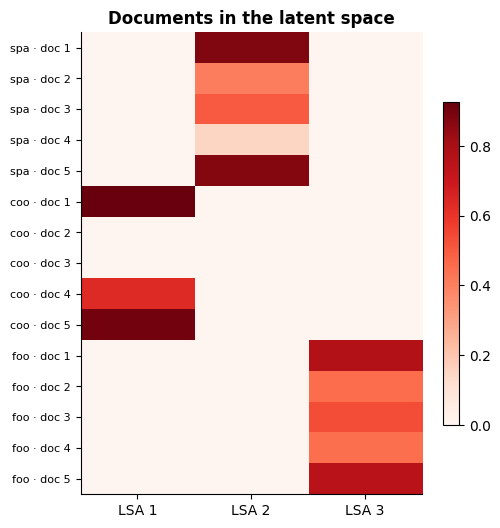

,representation,mean cosine similarity – same topic,mean cosine similarity – different topics
0,TF-IDF (word space),0.190,0.000
1,LSA (3 latent components),0.735,0.005


In [25]:
#Latent Semantic Analysis ( TruncatedSVD on TF-IDF )
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

docs = [
    # space
    "rocket launch into orbit carrying a satellite for the space mission",
    "astronauts live on the space station in orbit around the planet earth",
    "the mars rover mission explores the planet surface for the space agency",
    "the telescope observes a distant galaxy and a bright star in space",
    "the satellite orbit and the rocket launch were part of the mars mission",
    # cooking
    "bake the cake in the oven with flour sugar and butter",
    "fry the onions and garlic in olive oil then season the sauce with salt and pepper",
    "the chef seasoned the soup with salt pepper and fresh herbs",
    "knead the dough with flour and bake the bread in the oven",
    "mix butter sugar and flour for the cake then bake in a hot oven",
    # football
    "the striker scored a goal in the final minute of the football match",
    "the goalkeeper saved a penalty and the team won the football championship",
    "the coach changed the tactics and the team scored another goal",
    "fans filled the stadium to watch the football league final match",
    "the team won the match with a late goal from the striker",
]
topics = np.repeat(["space", "cooking", "football"], 5)

tfidf = TfidfVectorizer(stop_words="english")
X_tfidf = tfidf.fit_transform(docs)                       # sparse matrix
print("TF-IDF matrix:", X_tfidf.shape, "(sparse)")

lsa = TruncatedSVD(n_components=3, random_state=RANDOM_STATE)
Z_lsa = lsa.fit_transform(X_tfidf)
terms = np.array(tfidf.get_feature_names_out())
for i, comp in enumerate(lsa.components_):
    print(f"component {i+1} top terms:", list(terms[np.argsort(comp)[::-1][:6]]))

# Documents x components: each topic "lights up" one latent component
fig, ax = plt.subplots(figsize=(5.5, 6))
im = ax.imshow(Z_lsa, cmap="Reds", aspect="auto")
ax.set_xticks(range(3)); ax.set_xticklabels([f"LSA {i+1}" for i in range(3)])
ax.set_yticks(range(len(docs))); ax.set_yticklabels([f"{t[:3]} · doc {i%5+1}" for i, t in enumerate(topics)], fontsize=8)
ax.grid(False); ax.set_title("Documents in the latent space"); fig.colorbar(im, ax=ax, shrink=0.7)
plt.show()

# Do documents of the same topic become more similar?
from sklearn.metrics.pairwise import cosine_similarity
same = topics[:, None] == topics[None, :]
off_diag = same & ~np.eye(len(topics), dtype=bool)
sim_rows = []
for name, M_ in [("TF-IDF (word space)", X_tfidf), ("LSA (3 latent components)", Z_lsa)]:
    S_ = cosine_similarity(M_)
    sim_rows.append((name, S_[off_diag].mean(), S_[~same].mean()))
pd.DataFrame(sim_rows, columns=["representation", "mean cosine similarity – same topic", "mean cosine similarity – different topics"])

Each component captured one **topic** and same-topic documents became **more similar**. The *savoury-cooking* documents (2 and 3) form a sub-topic that needs more components.

#### **`TruncatedSVD` vs `PCA`**

The same when the data are **centred**. `PCA` centres internally; `TruncatedSVD` does not (it preserves sparsity).

In [26]:
#TruncatedSVD vs PCA
Xc = X_wine_std - X_wine_std.mean(axis=0)
tsvd = TruncatedSVD(n_components=2, algorithm="arpack", random_state=RANDOM_STATE).fit(Xc)
print("TruncatedSVD on centred data == PCA :", np.allclose(np.abs(tsvd.components_), np.abs(PCA(2).fit(Xc).components_), atol=1e-6))

# Without centring, the first component mostly captures the *mean* of the data
tsvd_raw = TruncatedSVD(n_components=2, algorithm="arpack", random_state=RANDOM_STATE).fit(X_wine)
print("TruncatedSVD on RAW wine – variance ratio:", tsvd_raw.explained_variance_ratio_.round(3), "(dominated by scale/mean)")

TruncatedSVD on centred data == PCA : True
TruncatedSVD on RAW wine – variance ratio: [0.988 0.012] (dominated by scale/mean)


### **5. Rough Sets**

**Rough Set Theory** (Pawlak, 1982) handles **imprecise or inconsistent data** without extra assumptions (probabilities, membership degrees).

| Concept | Definition |
|---|---|
| **Decision table** | objects described by **condition attributes** $A$ and a **decision** $d$ |
| **Indiscernibility** | same values on $B \subseteq A$ → same **granule** $[x]_B$ |
| **Lower approximation** | $\underline{B}X = \{x \mid [x]_B \subseteq X\}$ – **certainly** in $X$ |
| **Upper approximation** | $\overline{B}X = \{x \mid [x]_B \cap X \neq \emptyset\}$ – **possibly** in $X$ |
| **Boundary** | $\overline{B}X - \underline{B}X$ (empty → exact set) |
| **Dependency** | $\gamma_B(d) = \lvert POS_B(d) \rvert \, / \, \lvert U \rvert$ (1 = fully determined) |
| **Reduct** | **minimal** $B$ with $\gamma_B(d) = \gamma_A(d)$ |
| **Core** | attributes present in **every** reduct |

#### **Example (Pawlak)**

Six patients, three symptoms and the diagnosis *Flu*.

In [27]:
#Create the Decision Table ( Pawlak Flu Example )
flu = pd.DataFrame({
    "Headache":    ["yes", "yes", "yes", "no",  "no",   "no"],
    "MusclePain":  ["yes", "yes", "yes", "yes", "no",   "yes"],
    "Temperature": ["normal", "high", "very_high", "normal", "high", "very_high"],
    "Flu":         ["no", "yes", "yes", "no", "no", "yes"],
}, index=["p1", "p2", "p3", "p4", "p5", "p6"])
flu

,Headache,MusclePain,Temperature,Flu
p1,yes,yes,normal,no
p2,yes,yes,high,yes
p3,yes,yes,very_high,yes
p4,no,yes,normal,no
p5,no,no,high,no
p6,no,yes,very_high,yes


#### **Building Blocks**

Granules, approximations, positive region and dependency $\gamma$.

In [28]:
#Functions: Granules, Approximations, Positive Region and Dependency
def indiscernibility_classes(df, attrs):
    """Partition of the universe into equivalence classes (granules) w.r.t. `attrs`."""
    if len(attrs) == 0:
        return [set(df.index)]
    gid = df.groupby(list(attrs), sort=False, dropna=False).ngroup()
    return [set(gid.index[gid == g]) for g in gid.unique()]

def approximations(df, attrs, target):
    """Lower and upper approximation of the set `target` (a collection of object ids)."""
    target = set(target)
    granules = indiscernibility_classes(df, attrs)
    lower = set().union(*[g for g in granules if g <= target])
    upper = set().union(*[g for g in granules if g & target])
    return lower, upper

def positive_region(df, attrs, decision):
    """Union of the lower approximations of every decision class."""
    pos = set()
    for value in df[decision].unique():
        lower, _ = approximations(df, attrs, df.index[df[decision] == value])
        pos |= lower
    return pos

def dependency(df, attrs, decision):
    """γ_B(d) = |POS_B(d)| / |U|  (fast version: objects whose granule has a single decision value)."""
    if len(attrs) == 0:
        return float(df[decision].nunique() == 1)
    n_decisions = df.groupby(list(attrs), dropna=False)[decision].transform("nunique")
    return float((n_decisions == 1).mean())

cond = ["Headache", "MusclePain", "Temperature"]
print("Granules for B = {Temperature}:")
for g in indiscernibility_classes(flu, ["Temperature"]):
    print("  ", sorted(g))

Granules for B = {Temperature}:
   ['p1', 'p4']
   ['p2', 'p5']
   ['p3', 'p6']


#### **Approximating "Flu = yes"**

$X = \{x : \text{Flu}(x) = \text{yes}\}$ approximated with different attribute sets $B$.

In [29]:
#Approximate the Concept Flu = yes
X_flu = flu.index[flu["Flu"] == "yes"]
print("X (Flu = yes) =", sorted(X_flu), "\n")

rows = []
for B in [["Temperature"], ["Headache", "MusclePain"], cond]:
    lower, upper = approximations(flu, B, X_flu)
    rows.append({"B": "{" + ", ".join(B) + "}", "lower": sorted(lower), "upper": sorted(upper),
                 "boundary": sorted(upper - lower),
                 "accuracy α": round(len(lower) / len(upper), 2),
                 "γ(Flu)": round(dependency(flu, B, "Flu"), 2)})
pd.DataFrame(rows)

X (Flu = yes) = ['p2', 'p3', 'p6'] 



,B,lower,upper,boundary,accuracy α,γ(Flu)
0,{Temperature},"[p3, p6]","[p2, p3, p5, p6]","[p2, p5]",0.5,0.67
1,"{Headache, MusclePain}",[],"[p1, p2, p3, p4, p6]","[p1, p2, p3, p4, p6]",0.0,0.17
2,"{Headache, MusclePain, Temperature}","[p2, p3, p6]","[p2, p3, p6]",[],1.0,1.00


With only `Temperature`, **p3, p6** *certainly* have the flu; **p2, p5** are in the **boundary** (same temperature, different diagnosis).

#### **Dependency of Every Subset**

In [30]:
#Dependency of the Decision for Every Subset of Attributes
rows = []
for k in range(1, len(cond) + 1):
    for B in combinations(cond, k):
        rows.append({"B": "{" + ", ".join(B) + "}", "size": k, "γ(Flu)": round(dependency(flu, list(B), "Flu"), 3)})
gamma_table = pd.DataFrame(rows).sort_values(["size", "γ(Flu)"], ascending=[True, False]).reset_index(drop=True)
gamma_table

,B,size,γ(Flu)
0,{Temperature},1,0.667
1,{MusclePain},1,0.167
2,{Headache},1,0.000
3,"{Headache, Temperature}",2,1.000
4,"{MusclePain, Temperature}",2,1.000
5,"{Headache, MusclePain}",2,0.167
6,"{Headache, MusclePain, Temperature}",3,1.000


#### **Discernibility Matrix**

Each cell lists the attributes that tell apart two objects with **different decisions**. A **reduct** must hit every cell; the **core** are the attributes that appear **alone** in a cell.

In [31]:
#Discernibility Matrix, Reducts and Core
def discernibility_cells(df, cond, decision):
    """Decision-relative discernibility matrix: one cell per pair of objects with different decisions
    (at least one of them in the positive region). Each cell = attributes that tell the two objects apart."""
    pos = positive_region(df, cond, decision)
    cells = {}
    for i, j in combinations(df.index, 2):
        if df.at[i, decision] != df.at[j, decision] and (i in pos or j in pos):
            cells[(i, j)] = frozenset(a for a in cond if df.at[i, a] != df.at[j, a])
    return cells

def reducts_from_cells(cells, cond):
    """All reducts = minimal attribute sets that intersect every non-empty cell."""
    sets = {s for s in cells.values() if s}
    minimal = [s for s in sets if not any(o < s for o in sets)]            # absorption law
    reducts = []
    for k in range(1, len(cond) + 1):
        for cand in combinations(cond, k):
            c = set(cand)
            if any(set(r) <= c for r in reducts):                          # already contains a reduct
                continue
            if all(c & s for s in minimal):
                reducts.append(cand)
    return reducts

cells = discernibility_cells(flu, cond, "Flu")

# Display as a symmetric matrix
objs = list(flu.index)
matrix = pd.DataFrame("", index=objs, columns=objs)
for (i, j), s in cells.items():
    text = "{" + ", ".join(sorted(s)) + "}"
    matrix.at[i, j] = text; matrix.at[j, i] = text
display(matrix)

reducts = reducts_from_cells(cells, cond)
core = set.intersection(*map(set, reducts))
print("Reducts:", reducts)
print("Core   :", core)

,p1,p2,p3,p4,p5,p6
p1,,{Temperature},{Temperature},,,"{Headache, Temperature}"
p2,{Temperature},,,"{Headache, Temperature}","{Headache, MusclePain}",
p3,{Temperature},,,"{Headache, Temperature}","{Headache, MusclePain, Temperature}",
p4,,"{Headache, Temperature}","{Headache, Temperature}",,,{Temperature}
p5,,"{Headache, MusclePain}","{Headache, MusclePain, Temperature}",,,"{MusclePain, Temperature}"
p6,"{Headache, Temperature}",,,{Temperature},"{MusclePain, Temperature}",


Reducts: [('Headache', 'Temperature'), ('MusclePain', 'Temperature')]
Core   : {'Temperature'}


Reducts: **{Headache, Temperature}** and **{MusclePain, Temperature}** · core: **{Temperature}**

#### **QuickReduct (Greedy)**

Adds the attribute that **raises $\gamma$ the most** (ties → finer partition), then drops the redundant ones. It finds *a* reduct, not necessarily the smallest.

In [32]:
#QuickReduct ( Greedy Search for a Reduct )
def quick_reduct(df, cond, decision):
    target = dependency(df, cond, decision)
    reduct, best = [], 0.0
    while best < target - 1e-12 and len(reduct) < len(cond):
        def score(a):                                   # largest gain in γ; ties → finer partition
            attrs = reduct + [a]
            return (dependency(df, attrs, decision), df.groupby(attrs, dropna=False).ngroups)
        a_best = max((a for a in cond if a not in reduct), key=score)
        reduct.append(a_best)
        best = dependency(df, reduct, decision)
    for a in list(reduct):                              # backward elimination of redundant attributes
        trial = [x for x in reduct if x != a]
        if trial and dependency(df, trial, decision) >= target - 1e-12:
            reduct = trial
    return reduct

print("QuickReduct on the flu table:", quick_reduct(flu, cond, "Flu"))

QuickReduct on the flu table: ['Temperature', 'Headache']


#### **Discretise First**

Rough sets need **discrete** attributes. With continuous values every object is its own granule and $\gamma$ is trivially 1 (see the `id` column).

In [33]:
#Rough Sets with Continuous Data ( Why Discretise )
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
iris_raw = iris.frame.rename(columns=lambda c: c.replace(" (cm)", "").replace(" ", "_"))   # sepal_length, ..., target
cond_iris = [c for c in iris_raw.columns if c != "target"]

iris_id = iris_raw.copy()
iris_id["id"] = range(len(iris_id))
print("γ({id}) on raw numeric data      :", dependency(iris_id, ["id"], "target"), "← useless: every object is unique")
print("γ({sepal_length}) on raw values   :", round(dependency(iris_raw, ["sepal_length"], "target"), 3), "← many tiny granules inflate γ")

γ({id}) on raw numeric data      : 1.0 ← useless: every object is unique
γ({sepal_length}) on raw values   : 0.213 ← many tiny granules inflate γ


`pd.qcut` into a few **quantile bins** restores meaningful granules:

In [34]:
#Discretise with Quantile Bins and Find the Reducts
def discretize(df, columns, bins=3):
    """Quantile discretisation into integer codes 0..bins-1."""
    out = df.copy()
    for c in columns:
        out[c] = pd.qcut(df[c], q=bins, labels=False, duplicates="drop").astype(int)
    return out

iris_disc = discretize(iris_raw, cond_iris, bins=3)
print("γ({sepal_length}) discretised    :", round(dependency(iris_disc, ["sepal_length"], "target"), 3))
print("γ(all four attributes)          :", round(dependency(iris_disc, cond_iris, "target"), 3))

reducts_iris = reducts_from_cells(discernibility_cells(iris_disc, cond_iris, "target"), cond_iris)
print("\nAll reducts of discretised Iris:", reducts_iris)
print("QuickReduct                     :", quick_reduct(iris_disc, cond_iris, "target"))

γ({sepal_length}) discretised    : 0.0
γ(all four attributes)          : 0.833

All reducts of discretised Iris: [('sepal_length', 'sepal_width', 'petal_length', 'petal_width')]
QuickReduct                     : ['petal_length', 'petal_width', 'sepal_width', 'sepal_length']


* $\gamma = 0.833$: with 3 bins, ≈ 17 % of the flowers fall in the **boundary** (same granule, different species)
* The only reduct is the **full set**: this table has no redundancy

#### **Rough Sets on Wine (13 Attributes)**

QuickReduct on Wine discretised into 3 bins.

In [35]:
#QuickReduct on the Wine Dataset ( Discretised )
wine_disc = discretize(X_wine.assign(target=y_wine.values), X_wine.columns, bins=3)
cond_wine = list(X_wine.columns)

gamma_full = dependency(wine_disc, cond_wine, "target")
reduct_wine = quick_reduct(wine_disc, cond_wine, "target")
print(f"γ(all 13 attributes) = {gamma_full:.3f}")
print(f"QuickReduct keeps {len(reduct_wine)} of {len(cond_wine)} attributes: {reduct_wine}")
print(f"γ(reduct) = {dependency(wine_disc, reduct_wine, 'target'):.3f}")

γ(all 13 attributes) = 1.000
QuickReduct keeps 5 of 13 attributes: ['alcohol', 'flavanoids', 'color_intensity', 'proline', 'malic_acid']
γ(reduct) = 1.000


A reduct computed on the **whole** data would leak information. `RoughSetSelector` finds it **inside each training fold** of a `Pipeline`.

In [36]:
#Rough Set Selector inside a Pipeline
class RoughSetSelector(BaseEstimator, TransformerMixin):
    """Attribute selection with the QuickReduct heuristic (after quantile discretisation)."""
    def __init__(self, n_bins=3):
        self.n_bins = n_bins

    def fit(self, X, y):
        X = pd.DataFrame(X).reset_index(drop=True)
        disc = discretize(X, X.columns, bins=self.n_bins)
        disc["__decision__"] = np.asarray(y)
        self.reduct_ = quick_reduct(disc, list(X.columns), "__decision__")
        return self

    def transform(self, X):
        return pd.DataFrame(X)[self.reduct_].to_numpy()

rs_pipe = make_pipeline(RoughSetSelector(n_bins=3), StandardScaler(), LogisticRegression(max_iter=1000))
rs_scores = cross_val_score(rs_pipe, X_wine, y_wine, cv=cv5)
full_scores = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), X_wine, y_wine, cv=cv5)
print(f"all 13 attributes : {full_scores.mean():.3f} ± {full_scores.std():.3f}")
print(f"Rough-set reduct  : {rs_scores.mean():.3f} ± {rs_scores.std():.3f}   (reducts per fold may differ slightly)")

all 13 attributes : 0.983 ± 0.014
Rough-set reduct  : 0.972 ± 0.025   (reducts per fold may differ slightly)


### **6. Comparing the Techniques**

All inside pipelines (no leakage), keeping 5 dimensions on Wine.

,technique,dimensions_kept,cv_accuracy,cv_std
0,baseline (13 attributes),13,0.983,0.014
1,PCA (5 components),5,0.978,0.021
2,TruncatedSVD (5 components),5,0.978,0.021
3,SelectKBest F-test (5),5,0.966,0.033
4,Rough-set reduct (QuickReduct),5,0.972,0.025


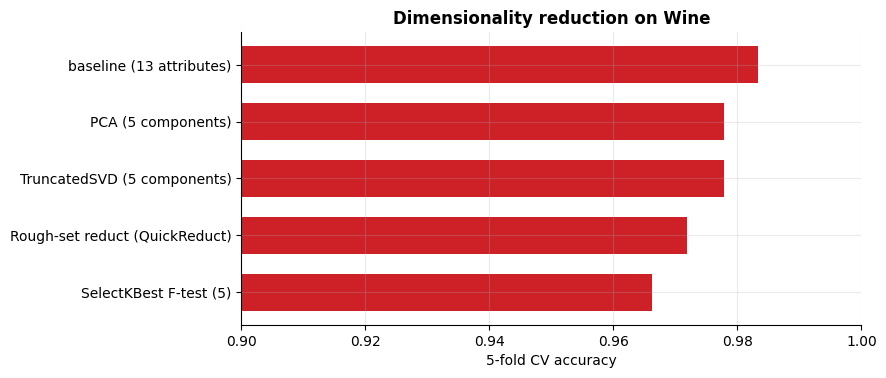

In [37]:
#Compare the Dimensionality Reduction Techniques
compare = {
    "baseline (13 attributes)":     make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "PCA (5 components)":           make_pipeline(StandardScaler(), PCA(n_components=5), LogisticRegression(max_iter=1000)),
    "TruncatedSVD (5 components)":  make_pipeline(StandardScaler(), TruncatedSVD(n_components=5, random_state=RANDOM_STATE), LogisticRegression(max_iter=1000)),
    "SelectKBest F-test (5)":       make_pipeline(StandardScaler(), SelectKBest(f_classif, k=5), LogisticRegression(max_iter=1000)),
    "Rough-set reduct (QuickReduct)": make_pipeline(RoughSetSelector(3), StandardScaler(), LogisticRegression(max_iter=1000)),
}
rows = []
for name, pipe in compare.items():
    s = cross_val_score(pipe, X_wine, y_wine, cv=cv5)
    kept = pipe[:-1].fit(X_wine, y_wine).transform(X_wine).shape[1]
    rows.append((name, kept, s.mean(), s.std()))
summary_dr = pd.DataFrame(rows, columns=["technique", "dimensions_kept", "cv_accuracy", "cv_std"])
display(summary_dr)

summary_dr.sort_values("cv_accuracy").plot.barh(x="technique", y="cv_accuracy", legend=False, color=RED, width=0.65, figsize=(8, 3.8))
plt.xlim(0.9, 1.0); plt.xlabel("5-fold CV accuracy"); plt.ylabel("")
plt.title("Dimensionality reduction on Wine")
plt.show()

| Criterion | **PCA** | **SVD** | **Rough Sets** |
|---|---|---|---|
| Type | Extraction | Extraction (factorisation) | **Selection** of attributes |
| Keeps original attributes? | No | No | **Yes** |
| Data type | Numeric | Numeric (also **sparse** matrices) | Discrete / categorical |
| Uses the target? | No | No | **Yes** (decision attribute) |
| Interpretability | Medium–low | Low | **High** |
| Typical use | Visualisation, removing correlation | Compression, text (LSA), recommendation | Reduce attributes while preserving classification |

### **7. Data Splitting and Validation**

Evaluate with data the model has **never seen**:

| Set | Role |
|---|---|
| **Training** | fits the model **and** the transformations (scaler, PCA, selectors…) |
| **Validation** | compares models / chooses **hyperparameters** |
| **Test** | final estimate, used **once** |

#### **Hold-Out and Stratification**

`train_test_split` with `stratify` keeps the class proportions.

In [38]:
#Hold-Out Split with Stratification
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

X_bc, y_bc = load_breast_cancer(return_X_y=True, as_frame=True)
print("Breast Cancer:", X_bc.shape, "| class balance:", y_bc.value_counts(normalize=True).round(3).to_dict())

X_train, X_test, y_train, y_test = train_test_split(
    X_bc, y_bc,
    test_size=0.2,          # 20% for the test set
    random_state=42,        # reproducibility
    stratify=y_bc)          # keep the class proportions in both sets

print("train:", X_train.shape, "| test:", X_test.shape)
print("class balance – train:", y_train.value_counts(normalize=True).round(3).to_dict())
print("class balance – test :", y_test.value_counts(normalize=True).round(3).to_dict())

Breast Cancer: (569, 30) | class balance: {1: 0.627, 0: 0.373}
train: (455, 30) | test: (114, 30)
class balance – train: {1: 0.626, 0: 0.374}
class balance – test : {1: 0.632, 0: 0.368}


With few samples and an **imbalanced** target, a random split can distort the test proportion (200 splits, 12 % positives):

% of positives in the test set (true proportion = 12%)
  without stratify: min 0% · max 30%
  with stratify   : min 10% · max 10%


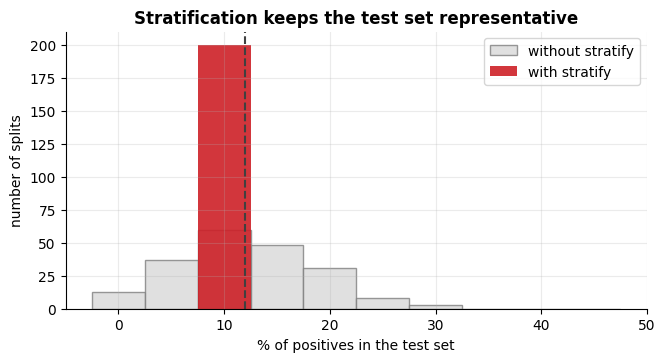

In [39]:
#Why Stratify Matters ( 200 Random Splits )
y_imb = np.r_[np.ones(12), np.zeros(88)]
X_imb = np.arange(100).reshape(-1, 1)

plain, strat = [], []
for seed in range(200):
    _, _, _, yt = train_test_split(X_imb, y_imb, test_size=0.2, random_state=seed)
    plain.append(yt.mean() * 100)
    _, _, _, yt = train_test_split(X_imb, y_imb, test_size=0.2, random_state=seed, stratify=y_imb)
    strat.append(yt.mean() * 100)

print(f"% of positives in the test set (true proportion = 12%)")
print(f"  without stratify: min {min(plain):.0f}% · max {max(plain):.0f}%")
print(f"  with stratify   : min {min(strat):.0f}% · max {max(strat):.0f}%")

plt.figure(figsize=(7.5, 3.6))
plt.hist(plain, bins=np.arange(-2.5, 50, 5), alpha=0.8, color=LIGHT, edgecolor=GRAY, label="without stratify")
plt.hist(strat, bins=np.arange(-2.5, 50, 5), alpha=0.9, color=RED, label="with stratify")
plt.axvline(12, color=DARK, ls="--"); plt.xlabel("% of positives in the test set"); plt.ylabel("number of splits"); plt.legend()
plt.title("Stratification keeps the test set representative")
plt.show()

#### **Train / Validation / Test**

Split twice (**70/15/15**): the **validation** set chooses `k`; the **test** set is used **once**.

In [40]:
#Train / Validation / Test Split ( 70 / 15 / 15 )
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_tmp, X_te, y_tmp, y_te = train_test_split(X_bc, y_bc, test_size=0.15, stratify=y_bc, random_state=42)
X_tr, X_va, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=0.15 / 0.85, stratify=y_tmp, random_state=42)
print(f"train {len(X_tr)} ({len(X_tr)/len(X_bc):.0%}) · validation {len(X_va)} ({len(X_va)/len(X_bc):.0%}) · test {len(X_te)} ({len(X_te)/len(X_bc):.0%})")

# 1) choose k using the VALIDATION set
val_scores = {}
for k in [1, 3, 5, 7, 11, 15, 21]:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X_tr, y_tr)
    val_scores[k] = model.score(X_va, y_va)
best_k = max(val_scores, key=val_scores.get)
print("validation accuracy by k:", {k: round(v, 3) for k, v in val_scores.items()})
print("best k:", best_k)

# 2) final evaluation on the TEST set, used only once
final = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k)).fit(X_tmp, y_tmp)   # train + validation
print(f"test accuracy (used once): {final.score(X_te, y_te):.3f}")

train 397 (70%) · validation 86 (15%) · test 86 (15%)
validation accuracy by k: {1: 0.965, 3: 0.965, 5: 0.977, 7: 0.977, 11: 0.965, 15: 0.977, 21: 0.965}
best k: 5
test accuracy (used once): 0.965


#### **Time Series**

Train on the **past**, test on the **future** – never shuffle. `TimeSeriesSplit` uses expanding windows.

split 1: train = [0…5] → test = [6…11]
split 2: train = [0…11] → test = [12…17]
split 3: train = [0…17] → test = [18…23]
split 4: train = [0…23] → test = [24…29]


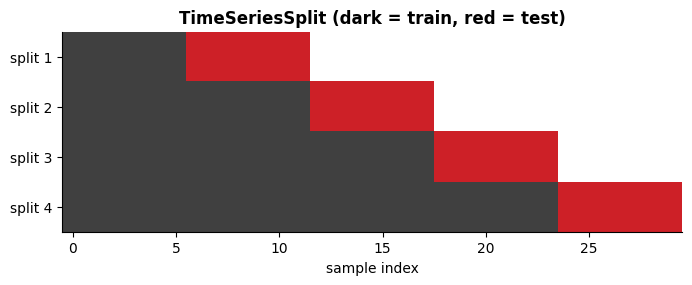

In [41]:
#TimeSeriesSplit ( Train on the Past, Test on the Future )
from sklearn.model_selection import KFold, StratifiedKFold, TimeSeriesSplit
from matplotlib.colors import ListedColormap

def plot_splits(cv, n_samples, ax, y=None, title=""):
    """Each row is one split: dark = training, red = test."""
    grid = np.full((cv.get_n_splits(), n_samples), np.nan)
    for i, (tr, te) in enumerate(cv.split(np.zeros(n_samples), y)):
        grid[i, tr] = 0; grid[i, te] = 1
    ax.imshow(grid, aspect="auto", cmap=ListedColormap([DARK, RED]), interpolation="nearest")
    ax.set_yticks(range(len(grid))); ax.set_yticklabels([f"split {i+1}" for i in range(len(grid))])
    ax.set_xlabel("sample index"); ax.set_title(title); ax.grid(False)

tscv = TimeSeriesSplit(n_splits=4)
for i, (tr, te) in enumerate(tscv.split(np.arange(30))):
    print(f"split {i+1}: train = [{tr[0]}…{tr[-1]}] → test = [{te[0]}…{te[-1]}]")

fig, ax = plt.subplots(figsize=(8, 2.6))
plot_splits(tscv, 30, ax, title="TimeSeriesSplit (dark = train, red = test)")
plt.show()

#### **Cross-Validation (k-Fold)**

*k–1* folds train, 1 fold validates; the *k* scores are averaged.

* `StratifiedKFold`: keeps the class proportions
* `GroupKFold`: keeps groups together
* `TimeSeriesSplit`: respects time

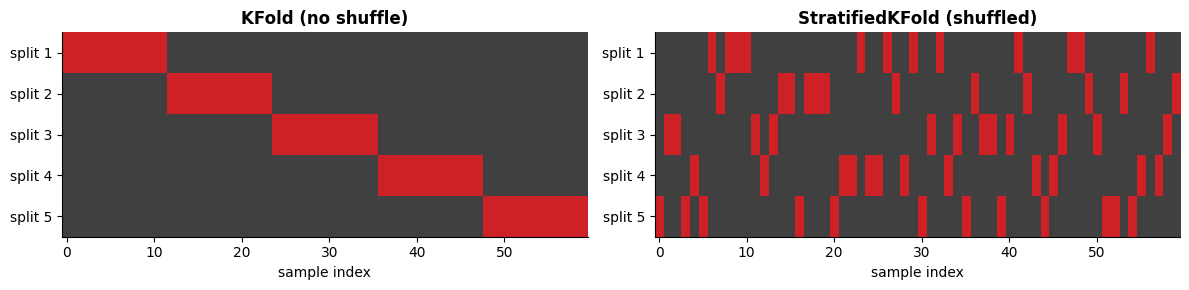

KFold            % of positives per test fold: [  0   0   0  25 100]
StratifiedKFold  % of positives per test fold: [25 25 25 25 25]


In [42]:
#KFold vs StratifiedKFold
rng = np.random.default_rng(RANDOM_STATE)
y_demo = np.r_[np.zeros(45), np.ones(15)]                  # imbalanced labels (25% positives)
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
plot_splits(KFold(5), 60, axes[0], y_demo, "KFold (no shuffle)")
plot_splits(StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), 60, axes[1], y_demo, "StratifiedKFold (shuffled)")
plt.tight_layout(); plt.show()

# proportion of positives in each TEST fold
for name, cv in [("KFold", KFold(5)), ("StratifiedKFold", StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))]:
    props = [y_demo[te].mean() for _, te in cv.split(np.zeros(60), y_demo)]
    print(f"{name:16s} % of positives per test fold:", np.round(np.array(props) * 100).astype(int))

In [43]:
#Cross-Validation with Several Metrics
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, cross_validate

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

scores = cross_val_score(model, X_bc, y_bc, cv=cv5)
print("accuracy per fold:", scores.round(3))
print(f"mean ± std       : {scores.mean():.3f} ± {scores.std():.3f}")

# several metrics at once (and the training score, useful to spot overfitting)
res = cross_validate(model, X_bc, y_bc, cv=cv5, scoring=["accuracy", "precision", "recall", "f1"], return_train_score=True)
pd.DataFrame(res).mean().round(3).to_frame("mean over 5 folds").T

accuracy per fold: [0.974 0.947 0.965 0.991 0.991]
mean ± std       : 0.974 ± 0.017


,fit_time,score_time,test_accuracy,train_accuracy,test_precision,train_precision,test_recall,train_recall,test_f1,train_f1
mean over 5 folds,0.071,0.039,0.974,0.988,0.968,0.986,0.992,0.995,0.979,0.991


#### **Data Leakage**

Information from outside the training set **leaks** into the model. Anything that **learns from data** (scaler, imputer, PCA, **feature selection**) must be fitted **only on the training part**.

Demo: the data are **random**, so the honest accuracy is ≈ 50 %. Selecting the best 20 of 5 000 features with **all** the labels gives a fake score.

In [44]:
#Data Leakage Demo with Pure Noise
from sklearn.feature_selection import SelectKBest, f_classif

rng = np.random.default_rng(0)
X_noise = rng.normal(size=(100, 5000))
y_noise = rng.integers(0, 2, size=100)

# ❌ WRONG: select features using ALL the data, then cross-validate
X_selected = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)
acc_wrong = cross_val_score(LogisticRegression(max_iter=1000), X_selected, y_noise, cv=5).mean()

# ✅ RIGHT: the selector is part of the Pipeline, so it is re-fitted inside each fold
pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
acc_right = cross_val_score(pipe, X_noise, y_noise, cv=5).mean()

print(f"leaky evaluation  : {acc_wrong:.3f}   ← fake performance on random data!")
print(f"correct (Pipeline): {acc_right:.3f}   ← ≈ 0.5, as it should be")

leaky evaluation  : 0.850   ← fake performance on random data!
correct (Pipeline): 0.480   ← ≈ 0.5, as it should be


**Golden rule:** put every learned transformation **inside a `Pipeline`**.

#### **PCA inside a Pipeline**

Scaler **and** PCA are refitted in each fold, using only its training part:

,n_components,cv_accuracy,cv_std
0,1,0.848,0.075
1,2,0.955,0.022
2,3,0.966,0.011
3,5,0.978,0.021
4,8,0.978,0.011
5,13,0.983,0.014


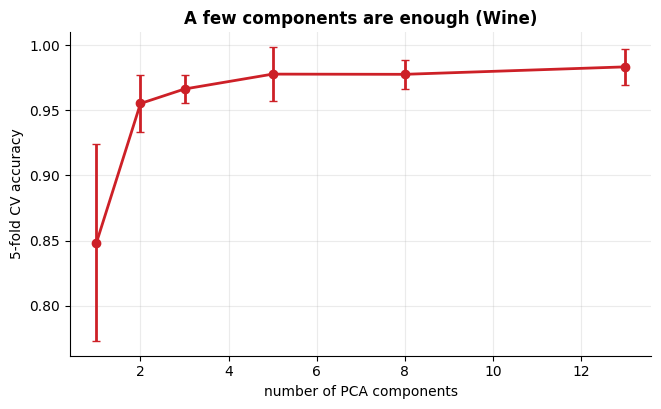

In [45]:
#PCA inside a Pipeline with Cross-Validation


rows = []
for n in [1, 2, 3, 5, 8, 13]:
    pipe = make_pipeline(StandardScaler(), PCA(n_components=n), LogisticRegression(max_iter=1000))
    s = cross_val_score(pipe, X_wine, y_wine, cv=cv5)
    rows.append((n, s.mean(), s.std()))
pca_cv = pd.DataFrame(rows, columns=["n_components", "cv_accuracy", "cv_std"])
display(pca_cv)

plt.figure()
plt.errorbar(pca_cv["n_components"], pca_cv["cv_accuracy"], yerr=pca_cv["cv_std"], marker="o", color=RED, lw=2, capsize=3)
plt.xlabel("number of PCA components"); plt.ylabel("5-fold CV accuracy")
plt.title("A few components are enough (Wine)")
plt.show()

### **Appendix – Pima Indians Diabetes (Optional)**

`diabetes.csv` used in class (768 patients, `Outcome` = diabetes). Needs internet; skipped if offline.

In [46]:
#Download the Pima Dataset ( Optional )
import io
from urllib.request import urlopen

PIMA_URL = "https://raw.githubusercontent.com/jrafa1607/DataScience-ML-AI/main/-%20Datasets/diabetes.csv"
try:
    pima = pd.read_csv(io.BytesIO(urlopen(PIMA_URL, timeout=10).read()))
    print("Loaded the Pima dataset:", pima.shape)
except Exception as exc:                                     # offline, blocked, ...
    pima = None
    print("Could not download the dataset (no internet?). The optional cells below will be skipped.")

Loaded the Pima dataset: (768, 9)


In [47]:
#PCA on Pima: Raw vs Standardised
if pima is not None:
    Xp, yp = pima.drop(columns="Outcome"), pima["Outcome"]

    # PCA on the raw attributes vs standardised attributes
    raw = PCA().fit(Xp)
    std = PCA().fit(StandardScaler().fit_transform(Xp))
    print("Variance explained by PC1 – raw attributes         :", round(raw.explained_variance_ratio_[0], 3))
    print("Variance explained by PC1 – standardised attributes:", round(std.explained_variance_ratio_[0], 3))
    print("Attribute with the largest weight in raw PC1       :", Xp.columns[np.abs(raw.components_[0]).argmax()], "(scale artefact)")
    print("Components for 95% of the variance (standardised)  :", int((std.explained_variance_ratio_.cumsum() < 0.95).sum() + 1))
else:
    print("skipped (dataset not available)")

Variance explained by PC1 – raw attributes         : 0.889
Variance explained by PC1 – standardised attributes: 0.262
Attribute with the largest weight in raw PC1       : Insulin (scale artefact)
Components for 95% of the variance (standardised)  : 8


In [48]:
#Rough Sets on Pima ( Discretised )
if pima is not None:
    cond_pima = list(pima.columns.drop("Outcome"))
    pima_disc = discretize(pima, cond_pima, bins=4)                 # quantile discretisation (rough sets need discrete data)

    print(f"γ(all 8 attributes) = {dependency(pima_disc, cond_pima, 'Outcome'):.3f}   (< 1: the table is inconsistent)")
    reduct_pima = quick_reduct(pima_disc, cond_pima, "Outcome")
    print("QuickReduct:", reduct_pima, f"| γ(reduct) = {dependency(pima_disc, reduct_pima, 'Outcome'):.3f}")

    rs = make_pipeline(RoughSetSelector(n_bins=4), StandardScaler(), LogisticRegression(max_iter=1000))
    base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    print("5-fold CV accuracy – all attributes:", round(cross_val_score(base, pima[cond_pima], pima["Outcome"], cv=cv5).mean(), 3))
    print("5-fold CV accuracy – rough-set reduct:", round(cross_val_score(rs, pima[cond_pima], pima["Outcome"], cv=cv5).mean(), 3))
else:
    print("skipped (dataset not available)")

γ(all 8 attributes) = 0.975   (< 1: the table is inconsistent)
QuickReduct: ['Pregnancies', 'Glucose', 'BMI', 'DiabetesPedigreeFunction', 'BloodPressure', 'Age', 'Insulin', 'SkinThickness'] | γ(reduct) = 0.975
5-fold CV accuracy – all attributes: 0.775
5-fold CV accuracy – rough-set reduct: 0.775
